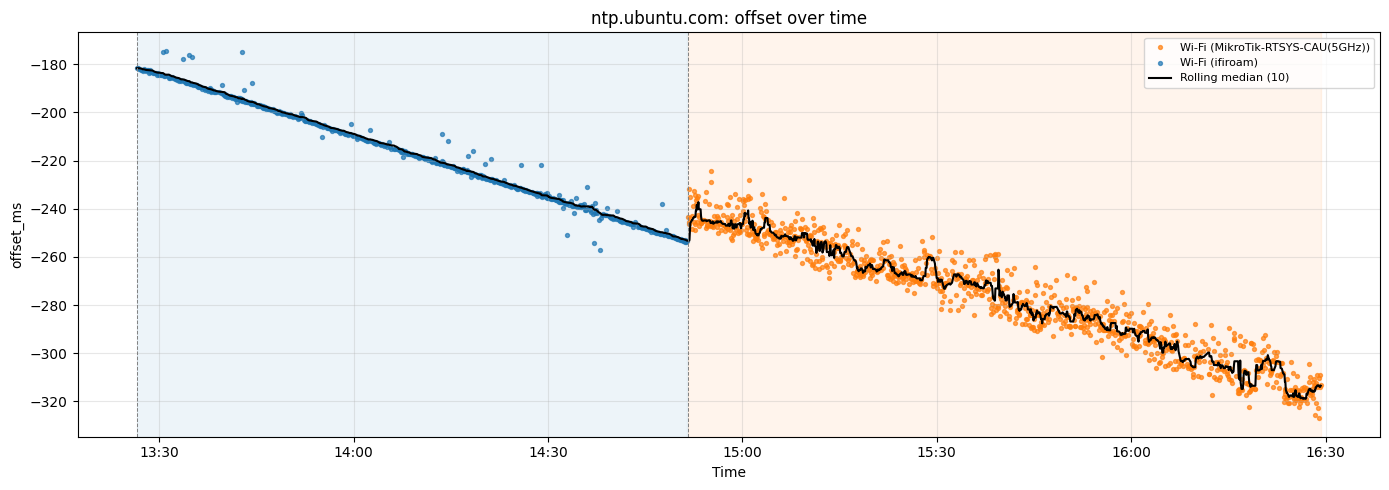

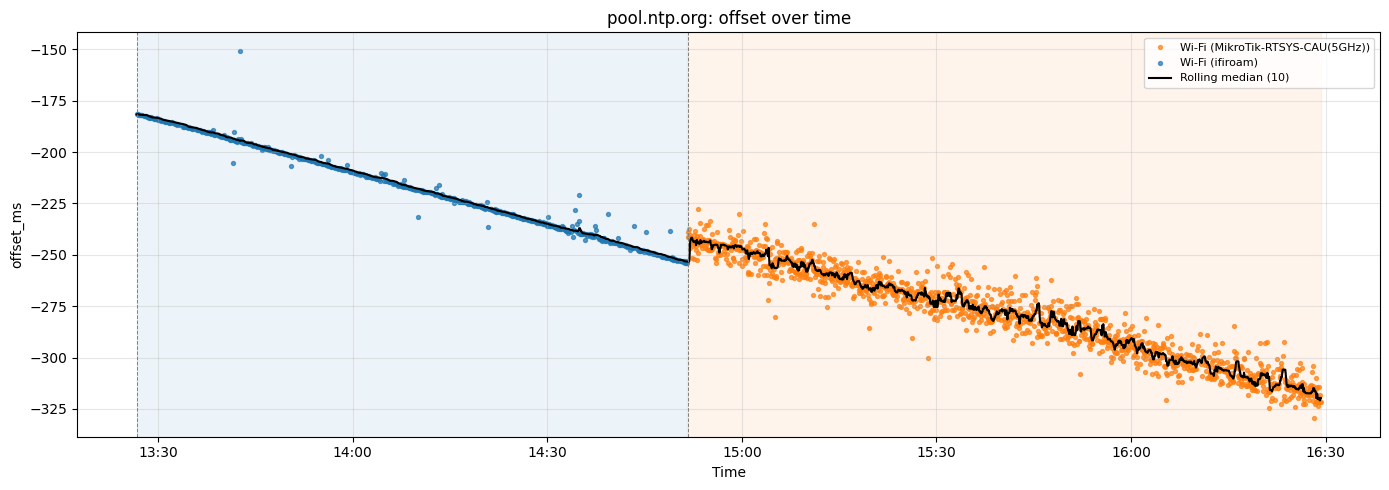

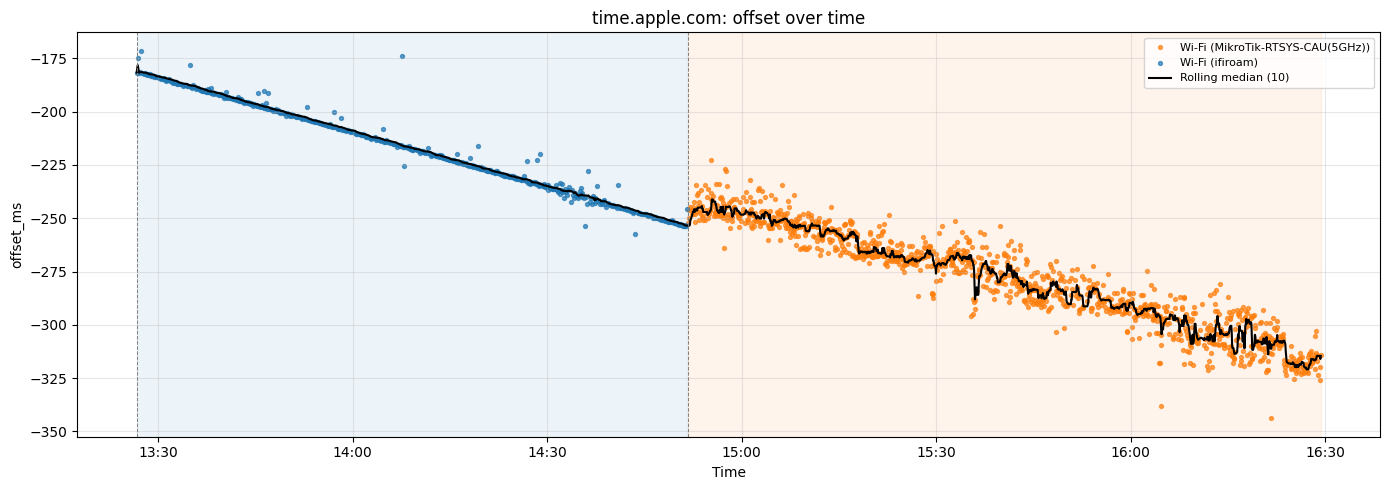

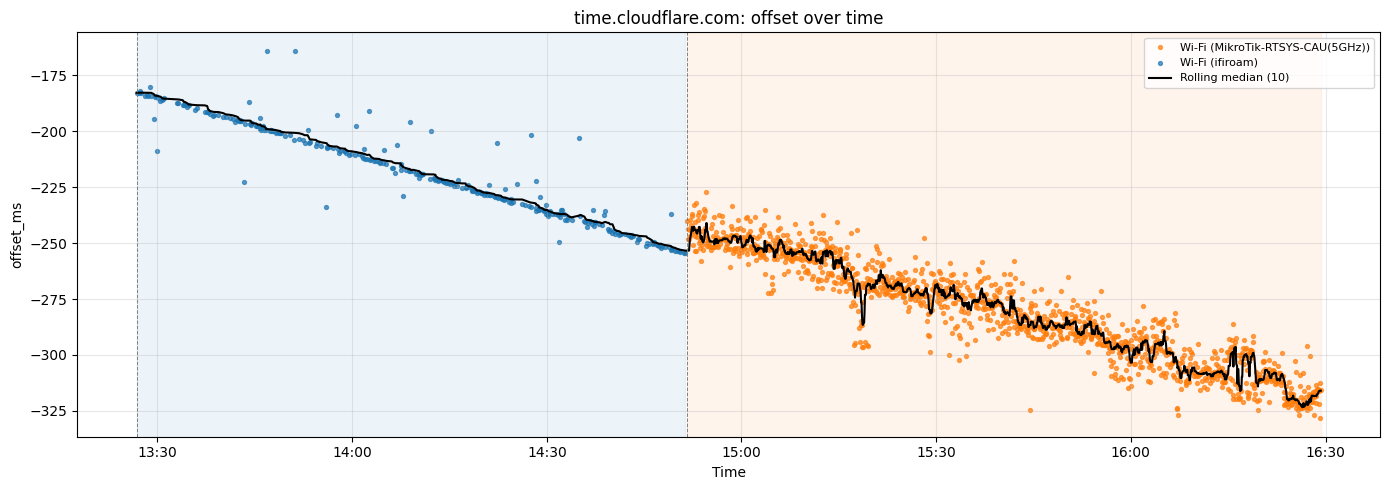

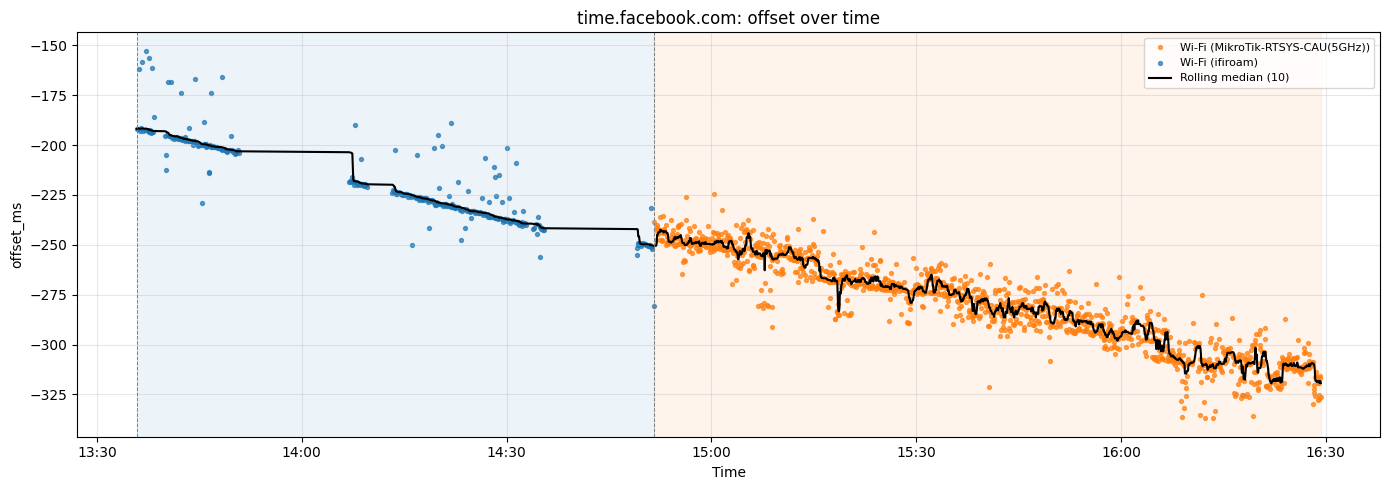

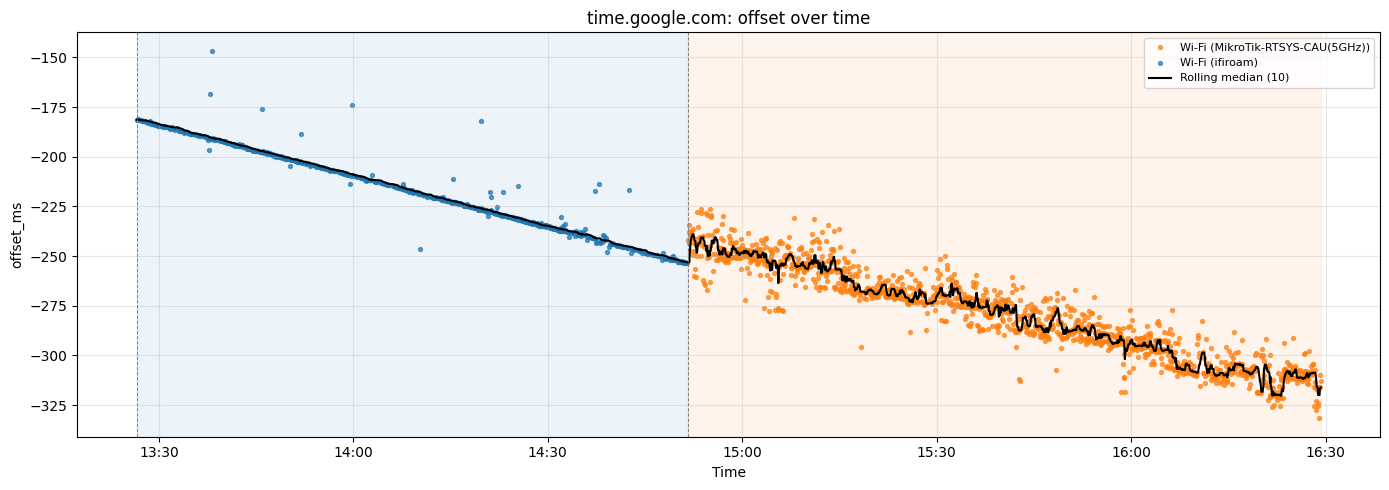

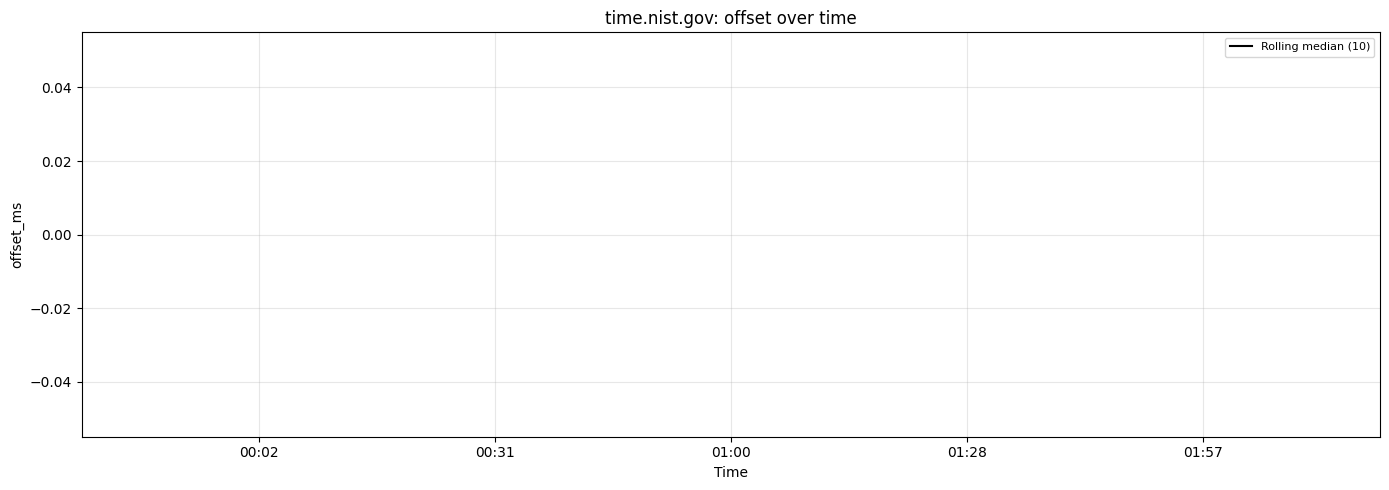

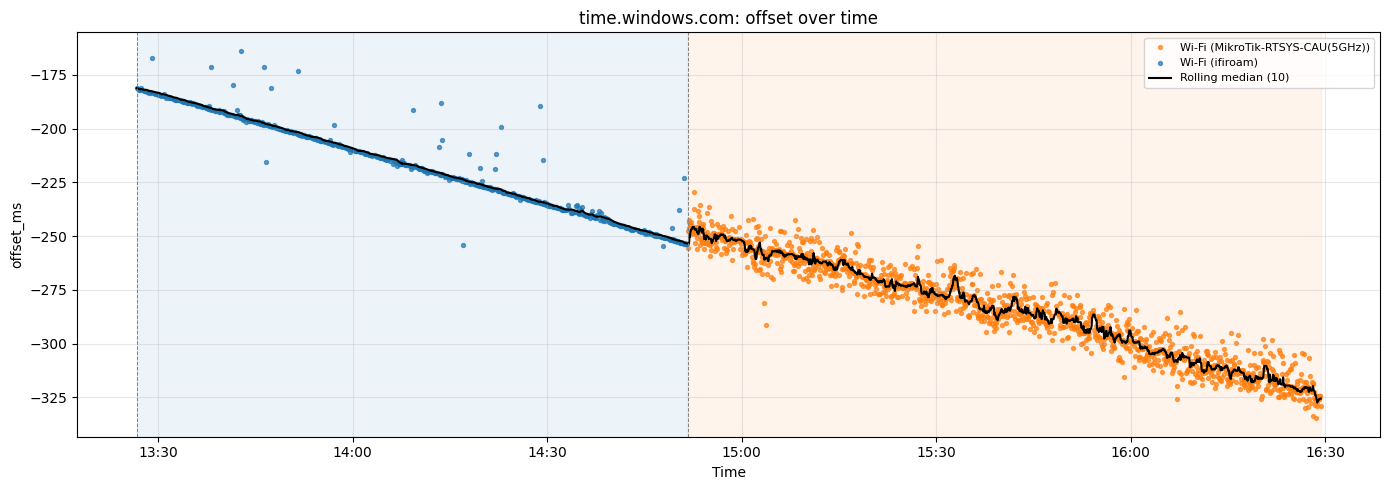

In [2]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# Folder containing one .jsonl file per NTP server
DATA_DIR = Path('../Desktop/20261102_132633_3Hours')
WINDOW = 10  # rolling median window (samples)
TZ = 'Europe/Berlin'


def load(path):
    df = pd.read_json(path, lines=True)
    df['time'] = pd.to_datetime(df['timestamp_ms'], unit='ms', utc=True).dt.tz_convert(TZ)
    return df.sort_values('time').reset_index(drop=True)


def plot_server(df, name):
    ok = df[df['is_success'] & df['offset_ms'].notna()].copy()
    ok['median'] = ok['offset_ms'].rolling(WINDOW, min_periods=1).median()

    fig, ax = plt.subplots(figsize=(14, 5))
    cmap = plt.get_cmap('tab10')
    names = list(ok['network_connection'].unique())
    for net, g in ok.groupby('network_connection'):
        ax.scatter(g['time'], g['offset_ms'], s=8, color=cmap(names.index(net) % 10), label=net, alpha=0.7)
    ax.plot(ok['time'], ok['median'], color='black', lw=1.5, label=f'Rolling median ({WINDOW})')

    # shade partitions where the network connection changes
    ok['segment'] = ok['network_connection'].ne(ok['network_connection'].shift()).cumsum()
    for _, seg in ok.groupby('segment'):
        c = cmap(names.index(seg['network_connection'].iloc[0]) % 10)
        ax.axvspan(seg['time'].iloc[0], seg['time'].iloc[-1], color=c, alpha=0.08)
        ax.axvline(seg['time'].iloc[0], color='gray', ls='--', lw=0.7)

    ax.set_title(f'{name}: offset over time')
    ax.set_xlabel('Time')
    ax.set_ylabel('offset_ms')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=TZ))
    ax.grid(alpha=0.3)
    ax.legend(loc='best', fontsize=8)
    fig.tight_layout()
    plt.show()


for f in sorted(DATA_DIR.glob('*.jsonl')):
    plot_server(load(f), f.stem)